# TP4 : Régression logistique — diagnostic du cancer du sein

Objectif : prédire si une tumeur est **maligne (M)** ou **bénigne (B)** à partir de 30 mesures des noyaux cellulaires (jeu de données *Breast Cancer Wisconsin (Diagnostic)*, Kaggle).

In [1]:
'''Commençons par faire appel à tous les outils nécessaires sous forme de bibliothèques
contenant des fonctions.'''

'Commençons par faire appel à tous les outils nécessaires sous forme de bibliothèques\ncontenant des fonctions.'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
'''
Nous chargeons les données des patients (téléchargées depuis Kaggle) pour les utiliser dans le notebook.
À l'aide de la commande `.head`, nous affichons les premières lignes de notre tableau.
À l'aide de la commande `.info()`, nous examinons la nature de nos données.
À l'aide de la commande `.isnull().sum()` vérifions s'il y a des valeurs manquantes..'''

"\nNous chargeons les données des patients (téléchargées depuis Kaggle) pour les utiliser dans le notebook.\nÀ l'aide de la commande `.head`, nous affichons les premières lignes de notre tableau.\nÀ l'aide de la commande `.info()`, nous examinons la nature de nos données.\nÀ l'aide de la commande `.isnull().sum()` vérifions s'il y a des valeurs manquantes.."

In [4]:
# Dans l'énoncé : pd.read_csv(r"c:\data.csv") ; ici le fichier est à côté du notebook
bc_df = pd.read_csv("data.csv")
bc_df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
bc_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [6]:
bc_df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [7]:
'''
À l'aide de la commande drop, nous supprimons les colonnes « id » et « Unnamed: 32 », car elles ne jouent aucun rôle dans la prédiction.
'''

"\nÀ l'aide de la commande drop, nous supprimons les colonnes « id » et « Unnamed: 32 », car elles ne jouent aucun rôle dans la prédiction.\n"

In [8]:
bc_df.drop(['Unnamed: 32', 'id'], axis = 1, inplace = True)

In [9]:
bc_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [10]:
'''
Ensuite, nous devons encoder les valeurs de la colonne « diagnosis » (qui se présentent actuellement sous la forme des lettres « M » et « B »)
en valeurs numériques : M (maligne) = 1, B (bénigne) = 0.
'''

'\nEnsuite, nous devons encoder les valeurs de la colonne « diagnosis » (qui se présentent actuellement sous la forme des lettres « M » et « B »)\nen valeurs numériques : M (maligne) = 1, B (bénigne) = 0.\n'

diagnosis
0    357
1    212
Name: count, dtype: int64


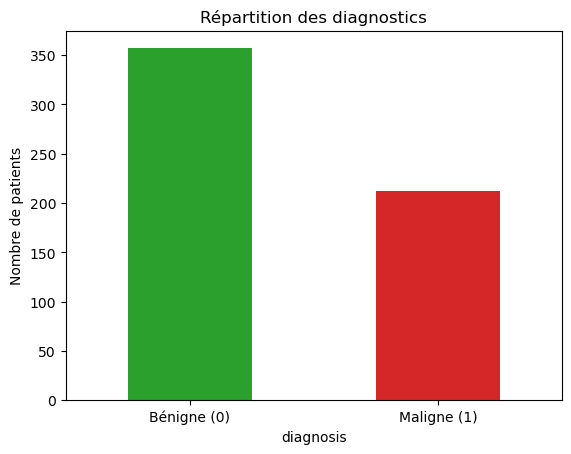

In [11]:
bc_df['diagnosis'] = bc_df['diagnosis'].map({'M': 1, 'B': 0})
print(bc_df['diagnosis'].value_counts())

bc_df['diagnosis'].value_counts().rename({0: 'Bénigne (0)', 1: 'Maligne (1)'}).plot(kind='bar', color=['tab:green', 'tab:red'])
plt.title('Répartition des diagnostics'); plt.ylabel('Nombre de patients'); plt.xticks(rotation=0)
plt.show()

In [12]:
'''
Nous séparons les caractéristiques X (30 mesures) de la cible y (diagnosis),
puis nous divisons les données en un ensemble d'entraînement (80 %) et un ensemble de test (20 %).
'''

"\nNous séparons les caractéristiques X (30 mesures) de la cible y (diagnosis),\npuis nous divisons les données en un ensemble d'entraînement (80 %) et un ensemble de test (20 %).\n"

In [13]:
from sklearn.model_selection import train_test_split

X = bc_df.drop('diagnosis', axis = 1)
y = bc_df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)
print("X_train :", X_train.shape, " X_test :", X_test.shape)

X_train : (455, 30)  X_test : (114, 30)


In [14]:
'''
Les variables n'ont pas la même échelle (area_mean ~ 1000, smoothness_mean ~ 0.1).
Nous les standardisons avec StandardScaler (moyenne 0, écart-type 1) pour que la régression logistique converge bien.
'''

"\nLes variables n'ont pas la même échelle (area_mean ~ 1000, smoothness_mean ~ 0.1).\nNous les standardisons avec StandardScaler (moyenne 0, écart-type 1) pour que la régression logistique converge bien.\n"

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

In [16]:
'''
Entraînement du modèle de régression logistique : P(y=1 | x) = 1 / (1 + exp(-(w·x + b)))
'''

'\nEntraînement du modèle de régression logistique : P(y=1 | x) = 1 / (1 + exp(-(w·x + b)))\n'

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter = 1000)
model.fit(X_train_sc, y_train)

LogisticRegression(max_iter=1000)

In [18]:
y_pred = model.predict(X_test_sc)
y_proba = model.predict_proba(X_test_sc)[:, 1]
print("Prédictions (20 premières) :", y_pred[:20])
print("Réel        (20 premiers)  :", y_test.values[:20])

Prédictions (20 premières) : [0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]
Réel        (20 premiers)  : [0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0]


In [19]:
'''
Évaluation du modèle : exactitude, matrice de confusion, précision, rappel, F1-score et courbe ROC.
'''

'\nÉvaluation du modèle : exactitude, matrice de confusion, précision, rappel, F1-score et courbe ROC.\n'

In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

print("Exactitude (train) : %.4f" % model.score(X_train_sc, y_train))
print("Exactitude (test)  : %.4f" % accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names = ['Bénigne (0)', 'Maligne (1)']))

Exactitude (train) : 0.9868
Exactitude (test)  : 0.9649

              precision    recall  f1-score   support

 Bénigne (0)       0.96      0.99      0.97        72
 Maligne (1)       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



[[71  1]
 [ 3 39]]


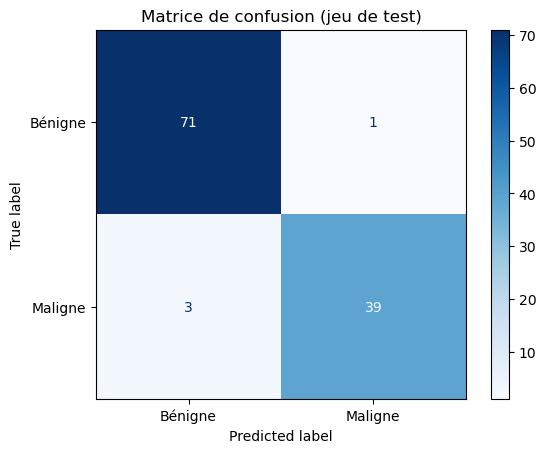

In [21]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels = ['Bénigne', 'Maligne']).plot(cmap = 'Blues')
plt.title('Matrice de confusion (jeu de test)')
plt.show()

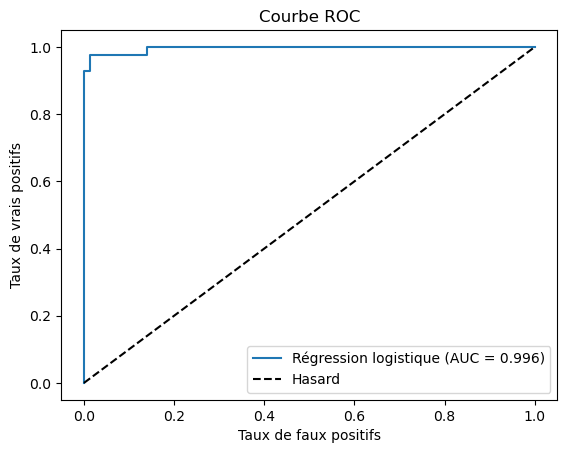

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)
plt.plot(fpr, tpr, label = 'Régression logistique (AUC = %.3f)' % auc)
plt.plot([0, 1], [0, 1], 'k--', label = 'Hasard')
plt.xlabel('Taux de faux positifs'); plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC'); plt.legend()
plt.show()

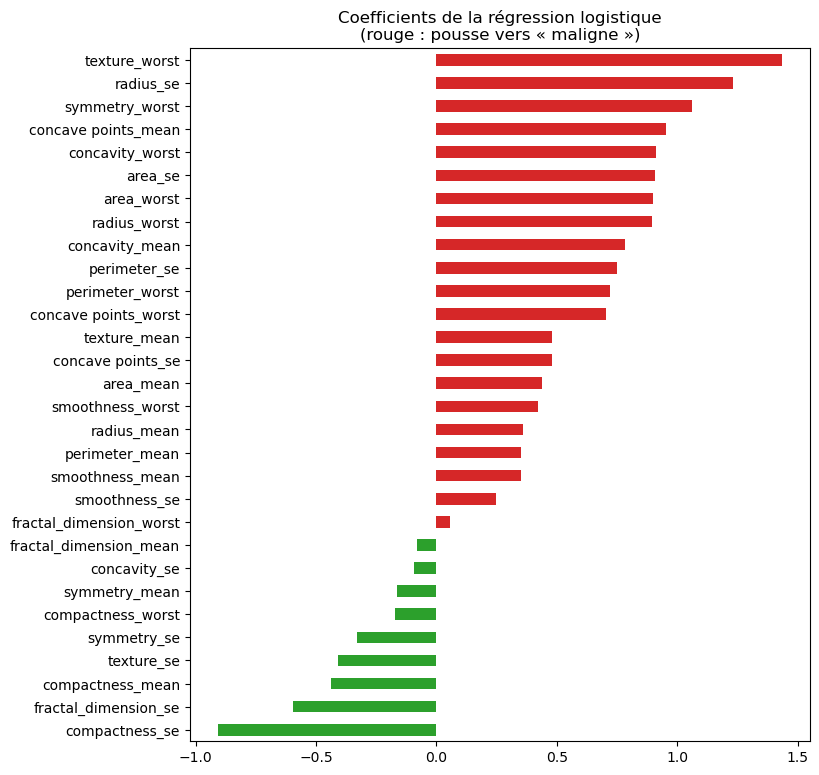

In [23]:
# Variables les plus influentes (coefficients sur données standardisées)
coefs = pd.Series(model.coef_[0], index = X.columns).sort_values()
coefs.plot(kind = 'barh', figsize = (8, 9), color = np.where(coefs > 0, 'tab:red', 'tab:green'))
plt.title('Coefficients de la régression logistique\n(rouge : pousse vers « maligne »)')
plt.show()

## Conclusion

- 569 patients (357 bénins, 212 malins), 30 variables, et aucune valeur manquante après suppression de `id` et `Unnamed: 32`.
- Une fois les données standardisées, la régression logistique classe très bien les tumeurs sur le jeu de test (voir l'exactitude, la matrice de confusion et l'AUC ci-dessus).
- Les variables qui comptent le plus sont liées à la taille et à la forme des noyaux (`radius`, `area`, `concave points`, `texture`…).